# PREDICTING HOUSE PRICE

|||
|---|---|
Student|Kennedy Kariuki Maina
Admn|DDA-03-0116/2025
Programme|Diploma in Data Science and Analytics
Department| SIME
Project| Machine learning model for predicting housing prices in kenya
Data| BuyRentkenya property listing(800 original + 8200 synthetic records)
Methodology| CRISP-DM


## BUSINESS UNDERSTANDING

### Problem Statement
Housing prices in Kenya vary depending on location, property size, number of bedrooms, amenities and other characteristics. Buyers and tenants may find it difficult to determine whether a property's asking price is reasonable. Nyumba Sense aims to address this challenge by using machine learning to estimate housing prices from available property information.

### Objectives
#### General
To develop a machine learning model for predicting house prices in Kenya using property listing data from BuyRent Kenya.
#### Specific Objectives
- To analyze the distribution and characteristics of house prices in the Kenyan real estate market.
- To identify the key features that influence house prices.
- To develop and evaluate machine learning models for house price prediction.
- To compare the performance of different machine learning algorithms in predicting house prices.


### Business Success Criteria
- Produce reasonable housing price estimates from property details.
- Identify important features associated with housing prices.
- Achieve acceptable predictive performance based on MAE, RMSE and R².

### Justification
A price-prediction tool gives buyers a way to judge whether an asking price is fair, helps sellers price realistically, and gives investors numbers instead of gut feeling.


### Tools and Resources
|Purpose|Tool|
|---|---|
Language|Python3
Library|pandas,Numpy,seaborn,matplotlib,SciPy,scikit-learn
Models|Random forest,Gradient Boosting

### Methodology
The project follows the CRISP-DM(Cross-Industry Standard Process for Data Mining)

## DATA UNDERSTANDING

### Data Collection
I attained the data from RubyRentKenya listing with 12 columns and 9,000 observation(800 original + 8200 synthetic records from an AI agent)

### Importing libraries and Loading dataset

In [107]:
# Import the necessary libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score, KFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

In [39]:
# Load the dataset
df = pd.read_csv("nyumba_sense_data.csv",encoding="latin1")
df

,Title,Property Type,Price,Location,Bedrooms,Bathrooms,Size,Amenities,Surroundings,Created At,URL,Record Type
0,3 Bed Townhouse with En Suite at Dagoretti Road,Townhouse,"KSh 22,500,000","Gikambura, Kikuyu",3 Bedrooms,3 Bathrooms,223 sqm,"Alarm, Backup Generator, En Suite, Fibre Inter...","Bus Stop, Hospital, Scenic View, School, Shopp...",21-Jan-26,https://www.buyrentkenya.com/listings/3-bedroo...,Original
1,4 Bed House in Kiambu Road,House,"KSh 78,000,000",Kiambu Road,4 Bedrooms,NaN,NaN,NaN,NaN,5-Dec-25,https://www.buyrentkenya.com/listings/4-bedroo...,Original
2,6 Bed Townhouse with En Suite in Lavington,Townhouse,"KSh 160,000,000",Lavington,6 Bedrooms,7 Bathrooms,450 sqm,"Alarm, Backup Generator, En Suite, Fibre Inter...","Bus Stop, Shopping Centre, Golf Course, Hospit...",6-Feb-26,https://www.buyrentkenya.com/listings/6-bedroo...,Original
3,4 Bed House with En Suite at Apple Cross,House,"KSh 130,000,000",Lavington,4 Bedrooms,5 Bathrooms,NaN,"Alarm, Backup Generator, Fibre Internet, En Su...","Bus Stop, Shopping Centre, Hospital, Scenic Vi...",18-Feb-26,https://www.buyrentkenya.com/listings/4-bedroo...,Original
4,2 Bed Villa with En Suite at Tembo Court,Villa,"KSh 21,000,000",Malindi,2 Bedrooms,3 Bathrooms,506 sqm,"Aircon, Alarm, Backup Generator, En Suite, Fib...","Bus Stop, Golf Course, Hospital, Scenic View, ...",17-Feb-26,https://www.buyrentkenya.com/listings/furnishe...,Original
...,...,...,...,...,...,...,...,...,...,...,...,...
8995,4 Bed House with En Suite in Syokimau,House,"KSh 33,343,535",Syokimau,4 Bedrooms,3 Bathrooms,NaN,"Alarm, Backup Generator, En Suite, Fibre Inter...","Bus Stop, Shopping Centre, Hospital, School",NaN,NaN,Synthetic
8996,4 Bed House with En Suite in Kiambu Road,House,"KSh 29,612,584",Kiambu Road,4 Bedrooms,6 Bathrooms,496 sqm,"En Suite, Fibre Internet, Walk In Closet, Back...","Bus Stop, Golf Course, Hospital, Scenic View, ...",NaN,NaN,Synthetic
8997,4 Bed Villa with En Suite at Off Loresho Ridge,Villa,"KSh 98,753,738","Loresho, Westlands",4 Bedrooms,5 Bathrooms,770 sqm,"Service Charge Included, Alarm, Backup Generat...","School, Scenic View, Hospital, Golf Course, Bu...",NaN,NaN,Synthetic
8998,4 Bed Townhouse with En Suite at Kimalat -Enka...,Townhouse,"KSh 14,719,230",Kitengela,4 Bedrooms,4 Bathrooms,168 sqm,"Alarm, Backup Generator, En Suite, Serviced, B...","Bus Stop, Hospital, School, Shopping Centre",NaN,NaN,Synthetic


In [40]:
# Get the shape of the data
print(f"The dataset has {df.shape[1]} variables/columns with {df.shape[0]} observations/rows")

The dataset has 12 variables/columns with 9000 observations/rows


In [41]:
# The information about the variables
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9000 entries, 0 to 8999
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Title          9000 non-null   object
 1   Property Type  9000 non-null   object
 2   Price          9000 non-null   object
 3   Location       9000 non-null   object
 4   Bedrooms       9000 non-null   object
 5   Bathrooms      8627 non-null   object
 6   Size           5965 non-null   object
 7   Amenities      8713 non-null   object
 8   Surroundings   8096 non-null   object
 9   Created At     800 non-null    object
 10  URL            800 non-null    object
 11  Record Type    9000 non-null   object
dtypes: object(12)
memory usage: 843.9+ KB


In [42]:
# Attain the statistical summary of numeric variables
df.describe().T

,count,unique,top,freq
Title,9000,434,5 Bed Townhouse with En Suite in Lavington,911
Property Type,9000,3,House,3764
Price,9000,8370,"KSh 85,000,000",37
Location,9000,77,Lavington,2400
Bedrooms,9000,11,5 Bedrooms,3324
Bathrooms,8627,11,5 Bathrooms,2389
Size,5965,1382,20 sqm,1041
Amenities,8713,633,"Alarm, Backup Generator, En Suite, Fibre Inter...",472
Surroundings,8096,125,"Bus Stop, Golf Course, Hospital, Scenic View, ...",2028
Created At,800,85,17-Feb-26,94


In [43]:
# Missing value per column
miss = df.isnull().sum().to_frame('missing')
miss['% missing'] = (miss['missing'] / len(df) * 100).round(1)
display(miss.sort_values('% missing', ascending=False))

,missing,% missing
Created At,8200,91.1
URL,8200,91.1
Size,3035,33.7
Surroundings,904,10.0
Bathrooms,373,4.1
Amenities,287,3.2
Title,0,0.0
Property Type,0,0.0
Price,0,0.0
Location,0,0.0


In [44]:
# Original vs synthetic records
print(df['Record Type'].value_counts(), '\n')

Record Type
Synthetic    8200
Original      800
Name: count, dtype: int64 



In [45]:
# Check for duplicates
df.duplicated().sum()

6

## DATA CLEANING

In [46]:
# Drop the duplicates
df = df.drop_duplicates()

# re-check for duplicates
df.duplicated().sum()

0

In [77]:
# Create a copy so the raw data stays untouched
clean = df.copy().reset_index(drop=True)
print('Rows at start:', len(clean))

Rows at start: 8994


In [78]:
# Preview the copy
clean.head()

,Title,Property Type,Price,Location,Bedrooms,Bathrooms,Size,Amenities,Surroundings,Created At,URL,Record Type
0,3 Bed Townhouse with En Suite at Dagoretti Road,Townhouse,"KSh 22,500,000","Gikambura, Kikuyu",3 Bedrooms,3 Bathrooms,223 sqm,"Alarm, Backup Generator, En Suite, Fibre Inter...","Bus Stop, Hospital, Scenic View, School, Shopp...",21-Jan-26,https://www.buyrentkenya.com/listings/3-bedroo...,Original
1,4 Bed House in Kiambu Road,House,"KSh 78,000,000",Kiambu Road,4 Bedrooms,NaN,NaN,NaN,NaN,5-Dec-25,https://www.buyrentkenya.com/listings/4-bedroo...,Original
2,6 Bed Townhouse with En Suite in Lavington,Townhouse,"KSh 160,000,000",Lavington,6 Bedrooms,7 Bathrooms,450 sqm,"Alarm, Backup Generator, En Suite, Fibre Inter...","Bus Stop, Shopping Centre, Golf Course, Hospit...",6-Feb-26,https://www.buyrentkenya.com/listings/6-bedroo...,Original
3,4 Bed House with En Suite at Apple Cross,House,"KSh 130,000,000",Lavington,4 Bedrooms,5 Bathrooms,NaN,"Alarm, Backup Generator, Fibre Internet, En Su...","Bus Stop, Shopping Centre, Hospital, Scenic Vi...",18-Feb-26,https://www.buyrentkenya.com/listings/4-bedroo...,Original
4,2 Bed Villa with En Suite at Tembo Court,Villa,"KSh 21,000,000",Malindi,2 Bedrooms,3 Bathrooms,506 sqm,"Aircon, Alarm, Backup Generator, En Suite, Fib...","Bus Stop, Golf Course, Hospital, Scenic View, ...",17-Feb-26,https://www.buyrentkenya.com/listings/furnishe...,Original


#### Standardize the column names

In [79]:
clean.columns

Index(['Title', 'Property Type', 'Price', 'Location', 'Bedrooms', 'Bathrooms',
       'Size', 'Amenities', 'Surroundings', 'Created At', 'URL',
       'Record Type'],
      dtype='object')

In [80]:
# Make the column to be lower case
clean.columns = clean.columns.str.lower()

# Replace the space with underscore
clean.columns = clean.columns.str.replace(" ","_")
clean.columns

Index(['title', 'property_type', 'price', 'location', 'bedrooms', 'bathrooms',
       'size', 'amenities', 'surroundings', 'created_at', 'url',
       'record_type'],
      dtype='object')

#### Handle the text columns

In [81]:
# PRICES
print('Rows with no price:', (copy['price'] == 'Price not communicated').sum())
clean['price'] = pd.to_numeric(clean['price'].str.replace(r'[^\d.]', '', regex=True), errors='coerce')
clean = clean.dropna(subset=['price']).reset_index(drop=True)
print('Rows after dropping unpriced listings:', len(clean))

Rows with no price: 16
Rows after dropping unpriced listings: 8978


In [82]:
# BEDROOMS AND BATHROOM
for col in ['bedrooms', 'bathrooms']:
    clean[col] = pd.to_numeric(clean[col].str.extract(r'(\d+)')[0])   # missing bathrooms stay NaN

clean[['bedrooms', 'bathrooms']].describe()

,bedrooms,bathrooms
count,8978.000000,8617.000000
mean,4.461350,4.917489
std,1.088646,1.403849
min,1.000000,1.000000
25%,4.000000,4.000000
50%,4.000000,5.000000
75%,5.000000,6.000000
max,11.000000,11.000000


In [84]:
# SIZE: mixed units
def to_sqm(text):
    if pd.isna(text):
        return np.nan
    t = text.lower().replace(',', '').strip()
    m = re.match(r'^(\d+)\s*/\s*(\d+)', t)          # fractions such as 1/2 acre
    if m:
        value = int(m.group(1)) / int(m.group(2))
    else:
        m = re.match(r'^([\d.]+)', t)
        if not m:
            return np.nan
        value = float(m.group(1))
    if 'acre' in t:
        return value * 4046.86
    if 'sq ft' in t or 'sqft' in t:
        return value / 10.7639
    return value                                       # sqm or m²

import re
clean['size_sqm'] = clean['size'].apply(to_sqm)
print(clean['size'].str.extract(r'([a-zA-Z²]+(?: ft)?)')[0].value_counts(), '\n')
clean['size_sqm'].describe()

0
sqm      5787
acre      119
sq ft      33
m²          4
Name: count, dtype: int64 



count    5.943000e+03
mean     6.663212e+03
std      2.963177e+05
min      5.000000e+00
25%      1.600000e+02
50%      3.510000e+02
75%      5.240000e+02
max      2.023430e+07
Name: size_sqm, dtype: float64

In [86]:
print('Rows with exactly 20 sqm:', (clean['size_sqm'] == 20).sum())
print('Rows of 21-29 sqm:', clean['size_sqm'].between(21, 29.99).sum(), '(', (clean.loc[clean['size_sqm'].between(21, 29.99), 'record_type'] == 'Synthetic').mean().round(2), 'synthetic )')
print('Rows above 100 acres:', (clean['size_sqm'] > 100 * 4046.86).sum())

clean.loc[(clean['size_sqm'] < 30) | (clean['size_sqm'] > 100 * 4046.86), 'size_sqm'] = np.nan
clean['size_missing'] = clean['size_sqm'].isna().astype(int)
print('size missing now:', clean['size_missing'].sum(), f"({clean['size_missing'].mean():.0%})")

Rows with exactly 20 sqm: 1033
Rows of 21-29 sqm: 137 ( 1.0 synthetic )
Rows above 100 acres: 3
size missing now: 4212 (47%)


In [88]:
# REMAINING MISSING VALUE
clean['amenities'] = clean['amenities'].fillna('')
clean['surroundings'] = clean['surroundings'].fillna('')
clean['bathrooms_missing'] = clean['bathrooms'].isna().astype(int)

clean[['bathrooms', 'size_sqm', 'amenities', 'surroundings']].isnull().sum()


bathrooms        361
size_sqm        4212
amenities          0
surroundings       0
dtype: int64

In [92]:
# LOCATION
clean['location'] = clean['location'].str.strip()
parts = clean['location'].str.rsplit(',', n=1, expand=True)
clean['area'] = parts[1].fillna(parts[0]).str.strip()
clean['sub_location'] = parts[0].str.strip()

print('Unique locations:', clean['location'].nunique(),"\n",'Unique areas:', clean['area'].nunique())
clean['area'].value_counts().head(15)

Unique locations: 76 
 Unique areas: 52


area
Lavington        2400
Westlands        2121
Ruiru             752
Karen             557
Kitengela         520
Kiambu Road       322
Kileleshwa        277
Ongata Rongai     235
Ngong             204
Syokimau          184
Nyali             116
Kikuyu            113
Kilimani          102
Muthaiga           91
Watamu             67
Name: count, dtype: int64

In [93]:
# DATES
clean['created_at'] = pd.to_datetime(clean['created_at'], format='%d-%b-%y', errors='coerce')
clean['created_at'].describe()

count                              798
mean     2026-01-10 05:21:12.180451072
min                2019-07-12 00:00:00
25%                2026-01-29 00:00:00
50%                2026-02-06 00:00:00
75%                2026-02-13 00:00:00
max                2026-02-18 00:00:00
Name: created_at, dtype: object

In [95]:
# Logical check: more bathrooms than bedrooms + 2 is unusual
clean['Bath_gt_bed_plus2'] = (clean['bathrooms'] > clean['bedrooms'] + 2).astype(int)
print('Listings with bathrooms > bedrooms + 2:', clean['Bath_gt_bed_plus2'].sum())

Listings with bathrooms > bedrooms + 2: 208


In [96]:
# Price outliers on the log scale (IQR rule)
lp = np.log(clean['price'])
q1, q3 = lp.quantile([.25, .75])
iqr = q3 - q1
clean['Price_outlier'] = ((lp < q1 - 1.5 * iqr) | (lp > q3 + 1.5 * iqr)).astype(int)
print('Price outliers (log IQR):', clean['Price_outlier'].sum())

Price outliers (log IQR): 30


In [97]:
# Size outliers
ls = np.log(clean['size_sqm'])
q1, q3 = ls.quantile([.25, .75])
iqr = q3 - q1
clean['Size_outlier'] = ((ls < q1 - 1.5 * iqr) | (ls > q3 + 1.5 * iqr)).astype(int)
print('Size outliers (log IQR):', clean['Size_outlier'].sum())

Size outliers (log IQR): 606


In [98]:
clean.loc[clean['Price_outlier'] == 1, ['title', 'price', 'size_sqm', 'record_type']].sort_values('price').head(10)

,title,price,size_sqm,record_type
2380,5 Bed Villa with En Suite in Loresho,100000.0,7243.000000,Synthetic
4703,5 Bed Villa with En Suite in Loresho,100000.0,7763.000000,Synthetic
5410,5 Bed Villa with En Suite in Loresho,103189.0,8321.000000,Synthetic
4892,5 Bed Villa with En Suite in Loresho,105715.0,8524.000000,Synthetic
61,5 Bed Villa with En Suite in Loresho,108400.0,720.463772,Original
3269,5 Bed Villa with En Suite in Loresho,109974.0,7361.000000,Synthetic
6684,5 Bed Villa with En Suite in Loresho,115778.0,7658.000000,Synthetic
4369,5 Bed Villa with En Suite in Loresho,120250.0,7221.000000,Synthetic
7203,5 Bed Villa with En Suite in Loresho,126415.0,7145.000000,Synthetic
1822,5 Bed Villa with En Suite in Loresho,128396.0,7466.000000,Synthetic


In [100]:
# DUPLICATES AFTER CLEANING
key = ['property_type', 'price', 'location', 'bedrooms', 'bathrooms', 'size_sqm', 'amenities']
dup = clean.duplicated(subset=key, keep=False)
print(pd.crosstab(dup, clean['record_type'], rownames=['duplicate on key columns']))

record_type               Original  Synthetic
duplicate on key columns                     
False                          784       8180
True                            14          0


In [104]:
# Final check and save
final_cols = clean.columns
clean = clean[final_cols]
print(clean.shape)
display(clean.dtypes.to_frame('dtype').join(clean.isnull().sum().to_frame('missing')))
clean.to_csv('clean_data.csv', index=False)

(8978, 20)


,dtype,missing
title,object,0
property_type,object,0
price,float64,0
location,object,0
bedrooms,int64,0
bathrooms,float64,361
size,object,3035
amenities,object,0
surroundings,object,0
created_at,datetime64[ns],8180


In [103]:
# Load the cleaned version
clean.head()

,title,property_type,price,location,bedrooms,bathrooms,size,amenities,surroundings,created_at,url,record_type,size_sqm,size_missing,bathrooms_missing,area,sub_location,Bath_gt_bed_plus2,Price_outlier,Size_outlier
0,3 Bed Townhouse with En Suite at Dagoretti Road,Townhouse,22500000.0,"Gikambura, Kikuyu",3,3.0,223 sqm,"Alarm, Backup Generator, En Suite, Fibre Inter...","Bus Stop, Hospital, Scenic View, School, Shopp...",2026-01-21,https://www.buyrentkenya.com/listings/3-bedroo...,Original,223.0,0,0,Kikuyu,Gikambura,0,0,0
1,4 Bed House in Kiambu Road,House,78000000.0,Kiambu Road,4,NaN,NaN,,,2025-12-05,https://www.buyrentkenya.com/listings/4-bedroo...,Original,NaN,1,1,Kiambu Road,Kiambu Road,0,0,0
2,6 Bed Townhouse with En Suite in Lavington,Townhouse,160000000.0,Lavington,6,7.0,450 sqm,"Alarm, Backup Generator, En Suite, Fibre Inter...","Bus Stop, Shopping Centre, Golf Course, Hospit...",2026-02-06,https://www.buyrentkenya.com/listings/6-bedroo...,Original,450.0,0,0,Lavington,Lavington,0,0,0
3,4 Bed House with En Suite at Apple Cross,House,130000000.0,Lavington,4,5.0,NaN,"Alarm, Backup Generator, Fibre Internet, En Su...","Bus Stop, Shopping Centre, Hospital, Scenic Vi...",2026-02-18,https://www.buyrentkenya.com/listings/4-bedroo...,Original,NaN,1,0,Lavington,Lavington,0,0,0
4,2 Bed Villa with En Suite at Tembo Court,Villa,21000000.0,Malindi,2,3.0,506 sqm,"Aircon, Alarm, Backup Generator, En Suite, Fib...","Bus Stop, Golf Course, Hospital, Scenic View, ...",2026-02-17,https://www.buyrentkenya.com/listings/furnishe...,Original,506.0,0,0,Malindi,Malindi,0,0,0


## EXPLORATORY DATA ANALYSIS(EDA)

In [121]:
sns.set_theme(style="whitegrid")
BLUE = "#2a6fb0"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Format KSh values in millions on axes
millions = FuncFormatter(lambda x, _: f"{x/1e6:,.0f}M")

In [105]:
# LOAD THE CLEANED VERSION
data = pd.read_csv("clean_data.csv")
data

,title,property_type,price,location,bedrooms,bathrooms,size,amenities,surroundings,created_at,url,record_type,size_sqm,size_missing,bathrooms_missing,area,sub_location,Bath_gt_bed_plus2,Price_outlier,Size_outlier
0,3 Bed Townhouse with En Suite at Dagoretti Road,Townhouse,22500000.0,"Gikambura, Kikuyu",3,3.0,223 sqm,"Alarm, Backup Generator, En Suite, Fibre Inter...","Bus Stop, Hospital, Scenic View, School, Shopp...",2026-01-21,https://www.buyrentkenya.com/listings/3-bedroo...,Original,223.0,0,0,Kikuyu,Gikambura,0,0,0
1,4 Bed House in Kiambu Road,House,78000000.0,Kiambu Road,4,NaN,NaN,NaN,NaN,2025-12-05,https://www.buyrentkenya.com/listings/4-bedroo...,Original,NaN,1,1,Kiambu Road,Kiambu Road,0,0,0
2,6 Bed Townhouse with En Suite in Lavington,Townhouse,160000000.0,Lavington,6,7.0,450 sqm,"Alarm, Backup Generator, En Suite, Fibre Inter...","Bus Stop, Shopping Centre, Golf Course, Hospit...",2026-02-06,https://www.buyrentkenya.com/listings/6-bedroo...,Original,450.0,0,0,Lavington,Lavington,0,0,0
3,4 Bed House with En Suite at Apple Cross,House,130000000.0,Lavington,4,5.0,NaN,"Alarm, Backup Generator, Fibre Internet, En Su...","Bus Stop, Shopping Centre, Hospital, Scenic Vi...",2026-02-18,https://www.buyrentkenya.com/listings/4-bedroo...,Original,NaN,1,0,Lavington,Lavington,0,0,0
4,2 Bed Villa with En Suite at Tembo Court,Villa,21000000.0,Malindi,2,3.0,506 sqm,"Aircon, Alarm, Backup Generator, En Suite, Fib...","Bus Stop, Golf Course, Hospital, Scenic View, ...",2026-02-17,https://www.buyrentkenya.com/listings/furnishe...,Original,506.0,0,0,Malindi,Malindi,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8973,4 Bed House with En Suite in Syokimau,House,33343535.0,Syokimau,4,3.0,NaN,"Alarm, Backup Generator, En Suite, Fibre Inter...","Bus Stop, Shopping Centre, Hospital, School",NaN,NaN,Synthetic,NaN,1,0,Syokimau,Syokimau,0,0,0
8974,4 Bed House with En Suite in Kiambu Road,House,29612584.0,Kiambu Road,4,6.0,496 sqm,"En Suite, Fibre Internet, Walk In Closet, Back...","Bus Stop, Golf Course, Hospital, Scenic View, ...",NaN,NaN,Synthetic,496.0,0,0,Kiambu Road,Kiambu Road,0,0,0
8975,4 Bed Villa with En Suite at Off Loresho Ridge,Villa,98753738.0,"Loresho, Westlands",4,5.0,770 sqm,"Service Charge Included, Alarm, Backup Generat...","School, Scenic View, Hospital, Golf Course, Bu...",NaN,NaN,Synthetic,770.0,0,0,Westlands,Loresho,0,0,0
8976,4 Bed Townhouse with En Suite at Kimalat -Enka...,Townhouse,14719230.0,Kitengela,4,4.0,168 sqm,"Alarm, Backup Generator, En Suite, Serviced, B...","Bus Stop, Hospital, School, Shopping Centre",NaN,NaN,Synthetic,168.0,0,0,Kitengela,Kitengela,0,0,0


In [ ]:
# Get the summary statistics for numeric values 
data.describe().T

,count,mean,std,min,25%,50%,75%,max
price,8978.0,8.306308e+07,7.292522e+07,100000.0,25548940.0,70000000.0,1.157828e+08,542500221.0
bedrooms,8978.0,4.461350e+00,1.088646e+00,1.0,4.0,4.0,5.000000e+00,11.0
bathrooms,8617.0,4.917489e+00,1.403849e+00,1.0,4.0,5.0,6.000000e+00,11.0
size_sqm,4766.0,1.274822e+03,7.827855e+03,38.0,270.0,427.0,6.290000e+02,404686.0
size_missing,8978.0,4.691468e-01,4.990750e-01,0.0,0.0,0.0,1.000000e+00,1.0
bathrooms_missing,8978.0,4.020940e-02,1.964609e-01,0.0,0.0,0.0,0.000000e+00,1.0
Bath_gt_bed_plus2,8978.0,2.316774e-02,1.504444e-01,0.0,0.0,0.0,0.000000e+00,1.0
Price_outlier,8978.0,3.341501e-03,5.771228e-02,0.0,0.0,0.0,0.000000e+00,1.0
Size_outlier,8978.0,6.749833e-02,2.508970e-01,0.0,0.0,0.0,0.000000e+00,1.0


### 1. Price Distribution

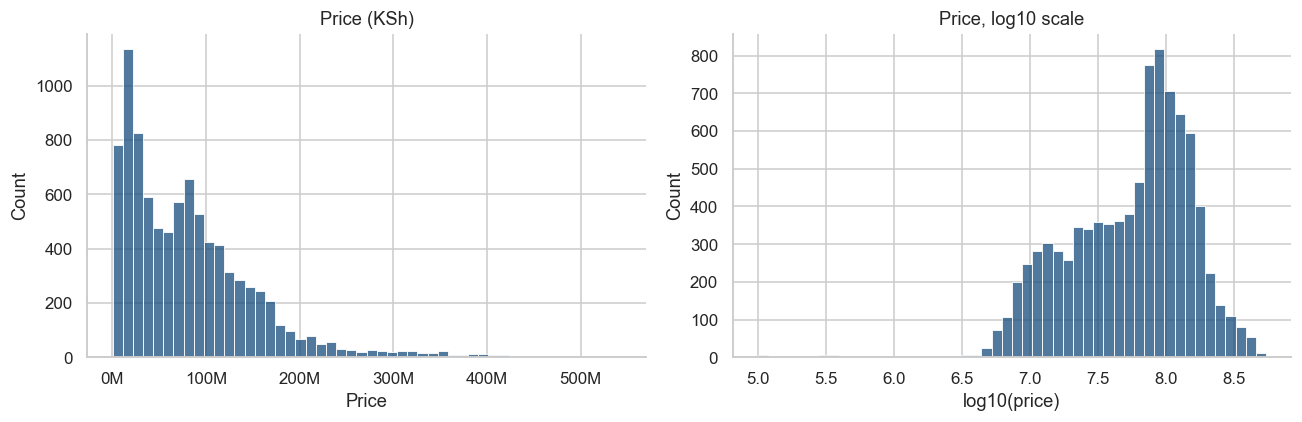

Skewness of price: 1.72
Skewness of log(price): -0.8


In [122]:

BLUE = "#174c7d"
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data["price"], bins=50, color=BLUE, ax=ax[0])
ax[0].xaxis.set_major_formatter(millions)
ax[0].set_title("Price (KSh)")
ax[0].set_xlabel("Price")

sns.histplot(np.log10(data["price"]), bins=50, color=BLUE, ax=ax[1])
ax[1].set_title("Price, log10 scale")
ax[1].set_xlabel("log10(price)")

plt.tight_layout()
plt.show()

print("Skewness of price:", round(data["price"].skew(), 2))
print("Skewness of log(price):", round(np.log(data["price"]).skew(), 2))


Price is right-skewed. A log transform makes it much more symmetric, which usually helps for modelling.

### 2.Bedrooms and Bathrooms

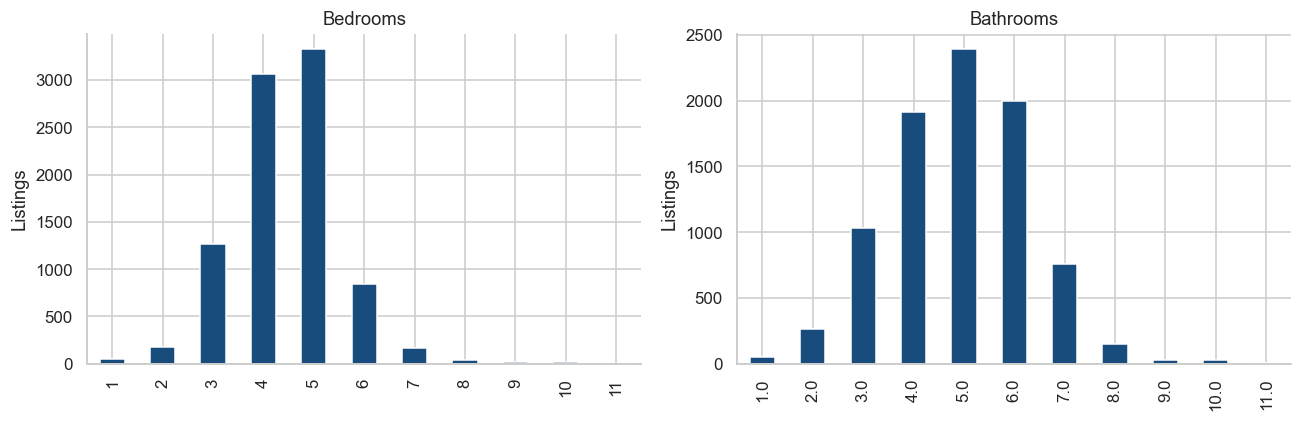

In [123]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

data["bedrooms"].value_counts().sort_index().plot.bar(color=BLUE, ax=ax[0])
ax[0].set_title("Bedrooms")
ax[0].set_xlabel("")
ax[0].set_ylabel("Listings")

data["bathrooms"].value_counts().sort_index().plot.bar(color=BLUE, ax=ax[1])
ax[1].set_title("Bathrooms")
ax[1].set_xlabel("")
ax[1].set_ylabel("Listings")

plt.tight_layout()
plt.show()


### 3.Size (sqm)

In [124]:
print("Rows with size:", data["size_sqm"].notna().sum())
print("Flagged size outliers:", data["Size_outlier"].sum())
print("Largest sizes:")
print(data["size_sqm"].nlargest(5).values)

Rows with size: 4766
Flagged size outliers: 606
Largest sizes:
[404686.  182108.7 161874.4 101171.5 101171.5]


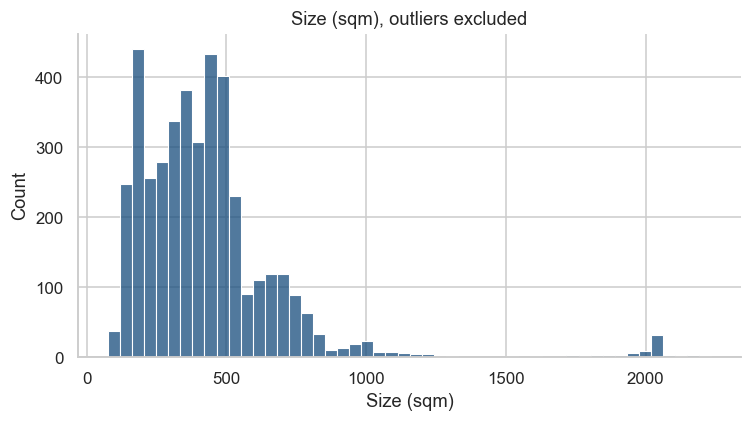

In [125]:
sized = data[(data["size_sqm"].notna()) & (data["Size_outlier"] == 0)]

fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(sized["size_sqm"], bins=50, color=BLUE, ax=ax)
ax.set_title("Size (sqm), outliers excluded")
ax.set_xlabel("Size (sqm)")
plt.tight_layout()
plt.show()

- The raw maximum is far beyond a plausible house size, which is why the outlier flag matters.
- Excluding flagged outliers gives a readable distribution.

### 4.Property type

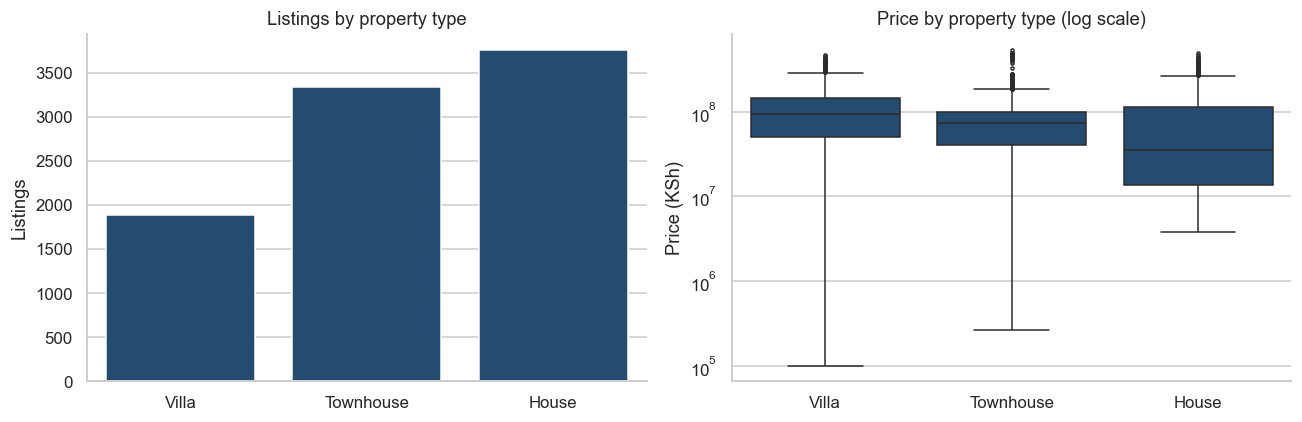

In [126]:
order = data.groupby("property_type")["price"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=data, x="property_type", order=order, color=BLUE, ax=ax[0])
ax[0].set_title("Listings by property type")
ax[0].set_xlabel("")
ax[0].set_ylabel("Listings")

sns.boxplot(data=data, x="property_type", y="price", order=order, color=BLUE, fliersize=2, ax=ax[1])
ax[1].set_yscale("log")
ax[1].set_title("Price by property type (log scale)")
ax[1].set_xlabel("")
ax[1].set_ylabel("Price (KSh)")

plt.tight_layout()
plt.show()

In [127]:
data.groupby("property_type")["price"].agg(["count", "median", "mean"]).round(0).loc[order]

,count,median,mean
property_type,,,
Villa,1889,94526462.0,104081381.0
Townhouse,3337,74110496.0,80044311.0
House,3752,35345893.0,75165967.0


### 5.Location

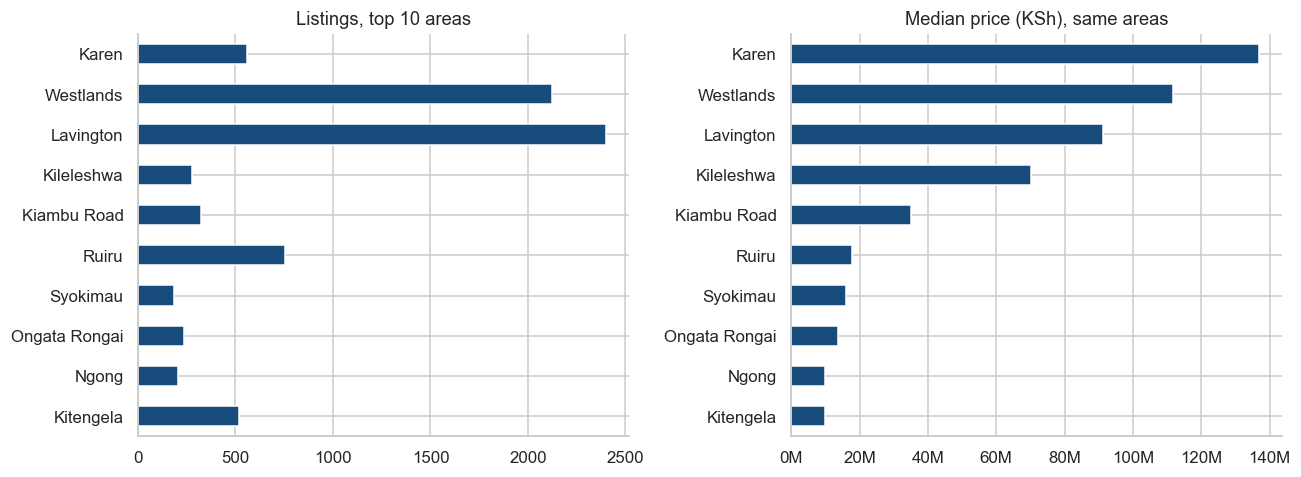

In [129]:
top = data["area"].value_counts().head(10).index
by_area = (data[data["area"].isin(top)]
           .groupby("area")["price"].agg(["count", "median"])
           .sort_values("median"))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

by_area["count"].plot.barh(color=BLUE, ax=ax[0])
ax[0].set_title("Listings, top 10 areas")
ax[0].set_ylabel("")

by_area["median"].plot.barh(color=BLUE, ax=ax[1])
ax[1].xaxis.set_major_formatter(millions)
ax[1].set_title("Median price (KSh), same areas")
ax[1].set_ylabel("")

plt.tight_layout()
plt.show()


In [130]:
by_area.sort_values("median", ascending=False)

,count,median
area,,
Karen,557,136897360.0
Westlands,2121,111590289.0
Lavington,2400,91362133.5
Kileleshwa,277,70112167.0
Kiambu Road,322,35150124.0
Ruiru,752,17851312.5
Syokimau,184,15969565.5
Ongata Rongai,235,13684849.0
Ngong,204,9991110.5


### 6.Relationships with price

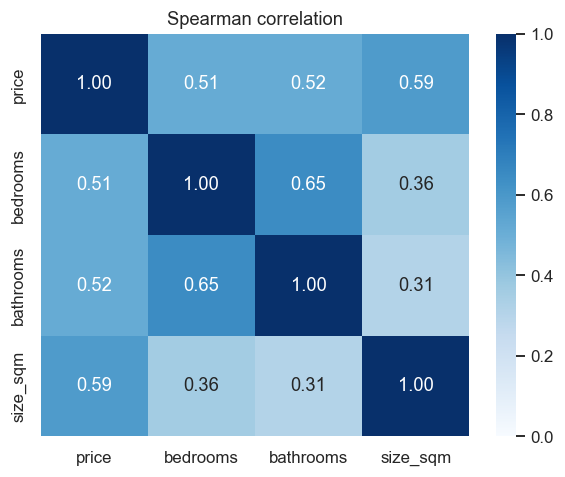

In [131]:
corr = data[["price", "bedrooms", "bathrooms", "size_sqm"]].corr(method="spearman")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title("Spearman correlation")
plt.tight_layout()
plt.show()

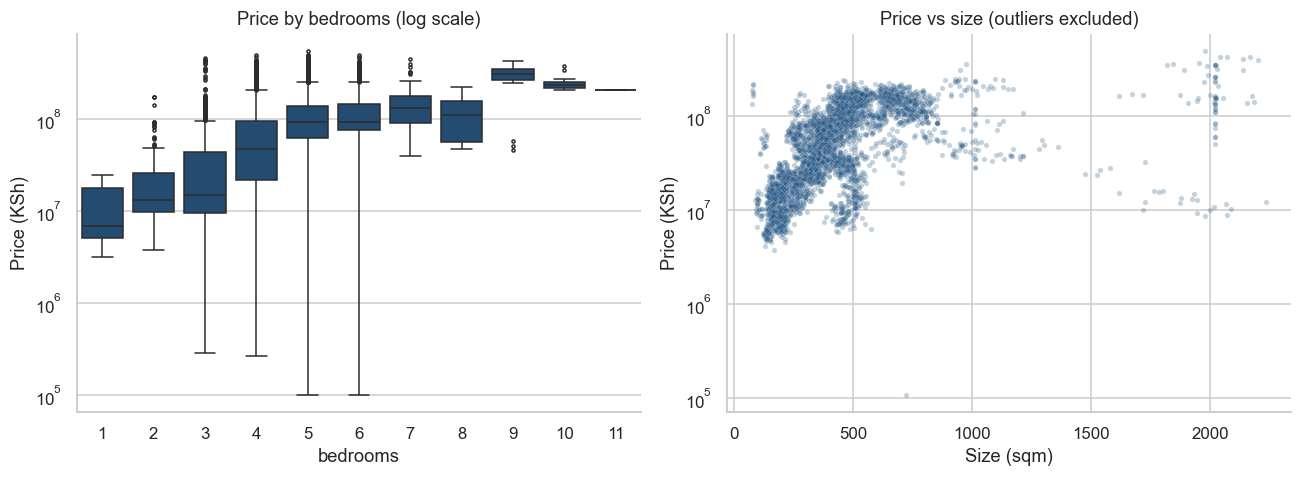

In [132]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

sns.boxplot(data=data, x="bedrooms", y="price", color=BLUE, fliersize=2, ax=ax[0])
ax[0].set_yscale("log")
ax[0].set_title("Price by bedrooms (log scale)")
ax[0].set_ylabel("Price (KSh)")

sns.scatterplot(data=sized, x="size_sqm", y="price", alpha=0.25, s=12, color=BLUE, ax=ax[1])
ax[1].set_yscale("log")
ax[1].set_title("Price vs size (outliers excluded)")
ax[1].set_xlabel("Size (sqm)")
ax[1].set_ylabel("Price (KSh)")

plt.tight_layout()
plt.show()

### 7.Original vs Synthetic

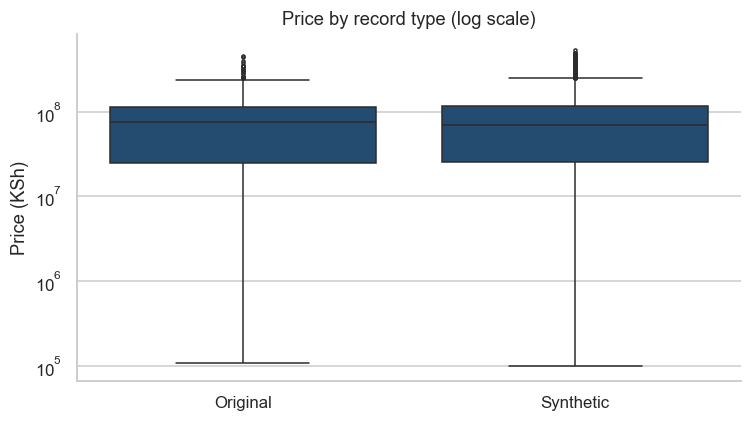

In [134]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=data, x="record_type", y="price", color=BLUE, fliersize=2, ax=ax)
ax.set_yscale("log")
ax.set_title("Price by record type (log scale)")
ax.set_xlabel("")
ax.set_ylabel("Price (KSh)")
plt.tight_layout()
plt.show()


In [135]:
data.groupby("record_type")[["price", "bedrooms", "bathrooms", "size_sqm"]].median()

,price,bedrooms,bathrooms,size_sqm
record_type,,,,
Original,74850000.0,4.0,5.0,476.0
Synthetic,69903537.5,4.0,5.0,422.0


### 8.Data quality flags

In [136]:
flags = ["size_missing", "bathrooms_missing", "Bath_gt_bed_plus2", "Price_outlier", "Size_outlier"]
data[flags].sum().to_frame("rows flagged").assign(pct=lambda d: (d["rows flagged"] / len(data) * 100).round(1))

,rows flagged,pct
size_missing,4212,46.9
bathrooms_missing,361,4.0
Bath_gt_bed_plus2,208,2.3
Price_outlier,30,0.3
Size_outlier,606,6.7


### Key Findings
1. **Mostly synthetic data.** 91% of rows (8,180 of 8,978) are synthetic and only 798 are original scraped listings. Their price, bedroom and bathroom medians are close, so the synthetic rows look consistent with the originals, but keep `record_type` in mind when you evaluate a model (for example, test on Original rows).
2. **Price is right-skewed.** Median is about KSh 70M against a mean of about KSh 83M, with a maximum of about KSh 542M. Skewness is 1.72 raw. On a log scale it is much more symmetric, so consider modelling `log(price)`.
3. **Price outliers.** 30 listings are priced between KSh 100K and KSh 720K, far too low for houses in this market, and they are likely entry errors. They show up as the long lower whiskers in the box plots.
4. **Size has a data problem.** The raw maximum of `size_sqm` is about 404,000 sqm (likely acres or land area entered as house size). With the 606 flagged outliers removed, the median is about 394 sqm. Size is also missing for 47% of rows.
5. **Location drives price.** Median price by area ranges from about KSh 10M (Kitengela, Ngong) to about KSh 137M (Karen). Lavington and Westlands are the two largest groups, at about 50% of listings together.
6. **Property type.** Villas are the priciest (median about KSh 95M), then Townhouses (about KSh 74M), then Houses (about KSh 35M). Houses have a very wide spread.
7. **Size and rooms.** Spearman correlation with price is 0.59 for size, 0.52 for bathrooms and 0.51 for bedrooms. Bedrooms and bathrooms are correlated with each other (0.65), so expect some multicollinearity in a linear model.
8. **Missing data.** Besides `size_sqm` (47%), `surroundings` is 10% missing, `bathrooms` 4% and `amenities` 3%. `created_at` and `url` are only present for Original rows.

